In [3]:
import pandas as pd

df = pd.read_csv("banknote-authentication.csv")

print(df.columns)


Index(['variance', 'skew', 'curtosis', 'entropy', 'class'], dtype='object')


In [21]:
print(df.shape)
print(df["class"].value_counts())

(1372, 5)
0    762
1    610
Name: class, dtype: int64


In [5]:
# seprate features and labels
X = df.drop("class", axis=1)
y = df["class"]

In [7]:
# split train and test sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)


X_train shape: (1097, 4)
X_test shape: (275, 4)


## Plot Gausian_Cantour to show features dependency

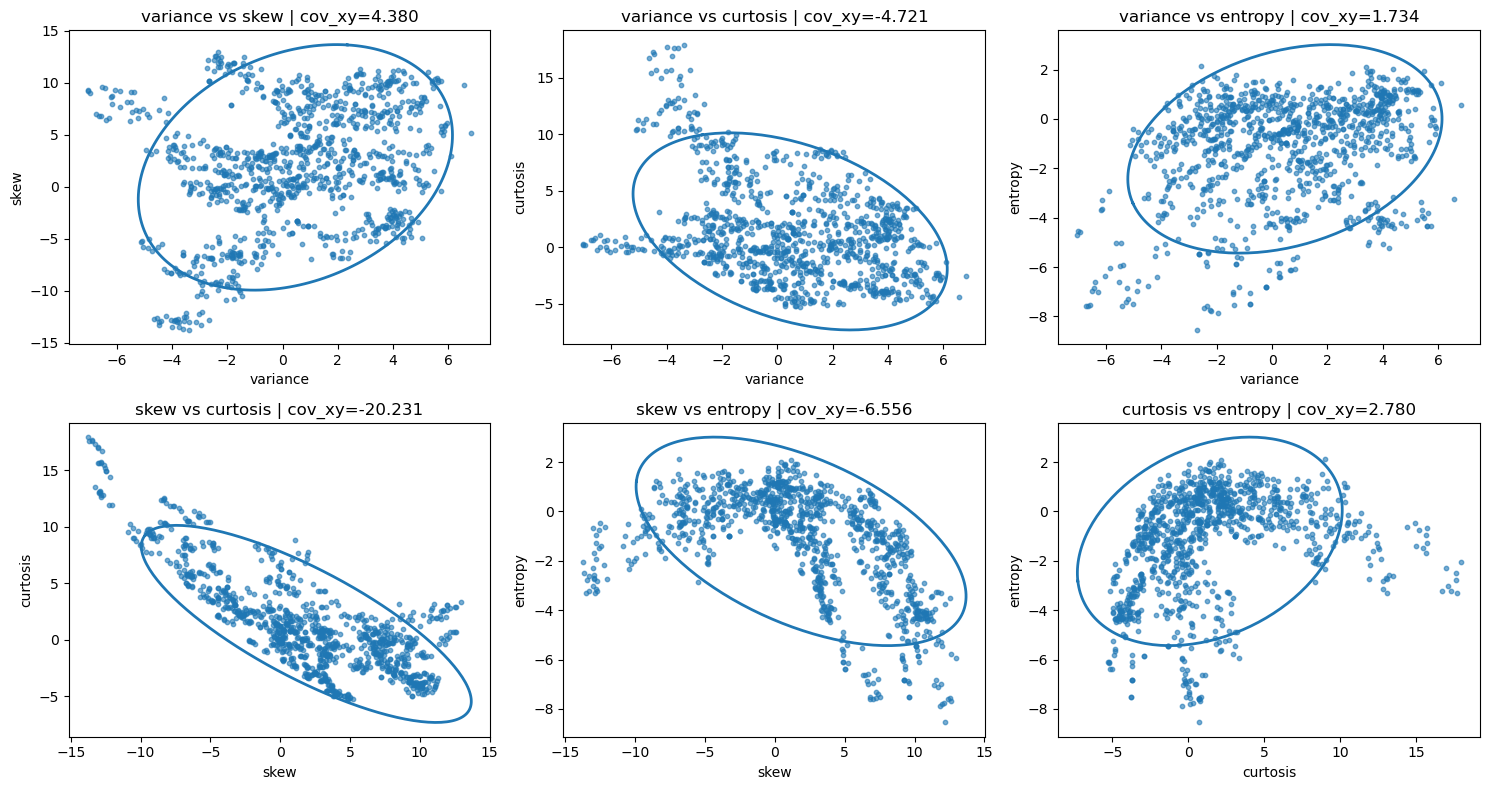

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# confidence ellipse from covariance
def plot_cov_ellipse(ax, x, y, n_std=2.0):
   
    x = np.asarray(x)
    y = np.asarray(y)

    mu = np.array([x.mean(), y.mean()])
    cov = np.cov(x, y)

    # Eigen-decomposition
    vals, vecs = np.linalg.eigh(cov)  # vals sorted ascending
    order = vals.argsort()[::-1]
    vals = vals[order]
    vecs = vecs[:, order]

    # Angle of major axis
    theta = np.degrees(np.arctan2(vecs[1, 0], vecs[0, 0]))

    # Width/height: 2*n_std*sqrt(eigenvalues)
    width, height = 2 * n_std * np.sqrt(vals)

    # Build ellipse points
    t = np.linspace(0, 2*np.pi, 200)
    ellipse = np.vstack([ (width/2)*np.cos(t), (height/2)*np.sin(t) ])

    # Rotate and shift
    R = np.array([
        [np.cos(np.radians(theta)), -np.sin(np.radians(theta))],
        [np.sin(np.radians(theta)),  np.cos(np.radians(theta))]
    ])
    ellipse = R @ ellipse
    ellipse[0, :] += mu[0]
    ellipse[1, :] += mu[1]

    ax.plot(ellipse[0, :], ellipse[1, :], linewidth=2)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    return cov


data_for_plot = X_train  #  X_train_clean

features = list(data_for_plot.columns)
pairs = []
for i in range(len(features)):
    for j in range(i+1, len(features)):
        pairs.append((features[i], features[j]))

# plot all pairs (6 for 4 features)
n = len(pairs)  
cols = 3
rows = int(np.ceil(n / cols))

fig, axes = plt.subplots(rows, cols, figsize=(5*cols, 4*rows))
axes = np.array(axes).reshape(-1)

for ax, (f1, f2) in zip(axes, pairs):
    x = data_for_plot[f1].values
    y = data_for_plot[f2].values

    ax.scatter(x, y, s=10, alpha=0.6)
    cov = plot_cov_ellipse(ax, x, y, n_std=2.0)

    ax.set_title(f"{f1} vs {f2} | cov_xy={cov[0,1]:.3f}")
    ax.set_xlabel(f1)
    ax.set_ylabel(f2)

# hide unused axes if any
for k in range(len(pairs), len(axes)):
    axes[k].axis("off")

plt.tight_layout()
plt.show()


### Multivariate Gaussian PDF (the method to detect outlier)

In [9]:
import numpy as np

# Multivariate Gaussian PDF(Probability Density Function)
def multivariate_gaussian_pdf(X, mu, Sigma):

    n = X.shape[1]
    X_mu = X - mu

    Sigma_inv = np.linalg.pinv(Sigma)
    det_Sigma = np.linalg.det(Sigma)

    if det_Sigma <= 0:
        det_Sigma = 1e-12

    coeff = 1 / (np.sqrt((2 * np.pi) ** n * det_Sigma))
    exp_term = np.exp(-0.5 * np.sum((X_mu @ Sigma_inv) * X_mu, axis=1))

    return coeff * exp_term


# Compute mu and Sigma from X_train
X_train_np = X_train.values

mu = np.mean(X_train_np, axis=0)
Sigma = np.cov(X_train_np, rowvar=False)

# Compute probability density for each sample
p_train = multivariate_gaussian_pdf(X_train_np, mu, Sigma)

# Choose epsilon (threshold)
epsilon = np.percentile(p_train, 1)

# Remove outliers
mask = p_train >= epsilon

X_train_clean = X_train.loc[mask].copy()
y_train_clean = y_train.loc[mask].copy()

# Report
n_before = X_train.shape[0]
n_after = X_train_clean.shape[0]
n_removed = n_before - n_after

print("Epsilon:", epsilon)
print(f"Train samples before outlier removal: {n_before}")
print(f"Train samples after outlier removal:  {n_after}")
print(f"Removed outliers: {n_removed} ({n_removed/n_before:.2%})")


Epsilon: 4.172445555957788e-07
Train samples before outlier removal: 1097
Train samples after outlier removal:  1086
Removed outliers: 11 (1.00%)


### Normalizing data by StandardScaler

In [11]:
# Normalizing data
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# fit on train
X_train_scaled = scaler.fit_transform(X_train_clean)

# transform on test
X_test_scaled = scaler.transform(X_test)

print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)


X_train_scaled shape: (1086, 4)
X_test_scaled shape: (275, 4)


In [13]:
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns, index=X_train_clean.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns, index=X_test.index)

print(X_train_scaled.head())


      variance      skew  curtosis   entropy
924   0.384368  0.040600 -1.062347  0.510656
1258 -0.399303 -0.246807 -0.402353  0.250032
342   1.250159 -0.303641 -0.093980  1.129865
1283 -0.124710 -0.323424 -0.715494  0.850143
1005 -1.206985 -0.448960  0.319944  1.222921


In [97]:
print(X_train_scaled.shape)


(1086, 4)


## PCA algorithm to reduce dimentionality

Explained Variance Ratio: [0.54678388 0.32168467 0.08592142 0.04561004]
Cumulative Variance: [0.54678388 0.86846855 0.95438996 1.        ]


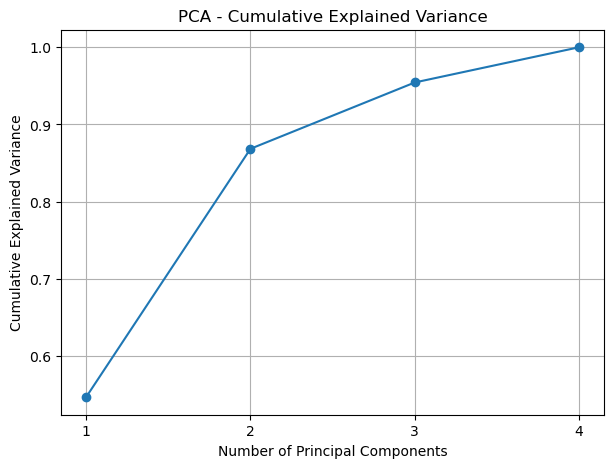

In [15]:
from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt

# PCA
pca_full = PCA()
pca_full.fit(X_train_scaled)

explained_variance_ratio = pca_full.explained_variance_ratio_
cum_variance = np.cumsum(explained_variance_ratio) # cumulative_variance

print("Explained Variance Ratio:", explained_variance_ratio)
print("Cumulative Variance:", cum_variance)

# plot cumulative variance
plt.figure(figsize=(7,5))
plt.plot(range(1, len(cum_variance)+1), cum_variance, marker='o')
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA - Cumulative Explained Variance")
plt.grid(True)
plt.xticks(range(1, len(cum_variance)+1))
plt.show()


In [17]:

keep_var = 0.80
n_components = np.argmax(cum_variance >= keep_var) + 1
print(f"Number of components to keep {keep_var*100}% variance:", n_components)

pca = PCA(n_components=n_components)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("X_train_pca shape:", X_train_pca.shape)
print("X_test_pca shape:", X_test_pca.shape)


Number of components to keep 80.0% variance: 2
X_train_pca shape: (1086, 2)
X_test_pca shape: (275, 2)


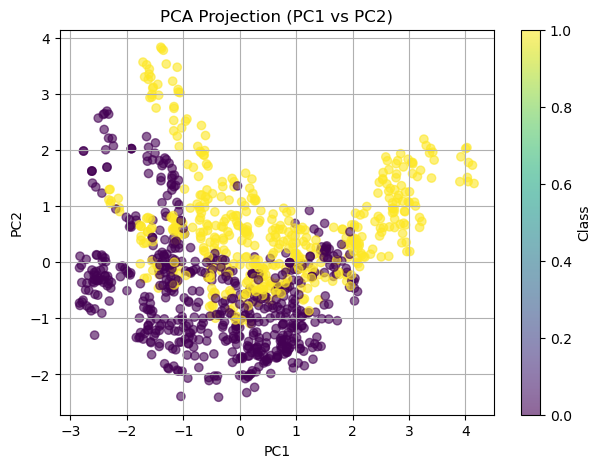

In [19]:
# plot reduced dimentional data
import matplotlib.pyplot as plt

plt.figure(figsize=(7,5))

plt.scatter(
    X_train_pca[:, 0],
    X_train_pca[:, 1],
    c=y_train_clean,
    alpha=0.6
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA Projection (PC1 vs PC2)")
plt.colorbar(label="Class")
plt.grid(True)
plt.show()


## Logestic algorithm with regularization parameter

In [87]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, log_loss


# Make a Validation Set (from training data)
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_scaled, y_train_clean,
    test_size=0.2,
    random_state=42,
    stratify=y_train_clean
)


C_list = [0.01, 0.1, 1, 10, 100] # lambda list

rows = []

# Train & Evaluate for each C (Machine Learning Examination)
# Compute Train/Val Accuracy + Train/Val Cost (Log Loss)
for C in C_list:
    model = LogisticRegression(C=C, max_iter=2000)  

    model.fit(X_tr, y_tr)

    # Predict probabilities (for Cost Function)
    p_tr = model.predict_proba(X_tr)
    p_val = model.predict_proba(X_val)

    # Predict labels (for Accuracy)
    y_tr_pred = model.predict(X_tr)
    y_val_pred = model.predict(X_val)

    # Cost (Cross-Entropy / Log Loss)
    train_cost = log_loss(y_tr, p_tr)
    val_cost = log_loss(y_val, p_val)

    # Accuracy
    train_acc = accuracy_score(y_tr, y_tr_pred)
    val_acc = accuracy_score(y_val, y_val_pred)

    # Gaps (useful for overfit/underfit discussion)
    acc_gap = train_acc - val_acc
    cost_gap = val_cost - train_cost

    rows.append({
        "C": C,
        "lambda(=1/C)": 1.0 / C,
        "Train Accuracy": train_acc,
        "Val Accuracy": val_acc,
        "Train Cost (LogLoss)": train_cost,
        "Val Cost (LogLoss)": val_cost,
        "Acc Gap (Train-Val)": acc_gap,
        "Cost Gap (Val-Train)": cost_gap
    })

results = pd.DataFrame(rows)

# sorting for report
results = results.sort_values(by="Val Cost (LogLoss)", ascending=True).reset_index(drop=True)


from IPython.display import display, HTML

# for report
table_for_report = results.copy()

# Round numbers
table_for_report["Train Accuracy"] = table_for_report["Train Accuracy"].round(4)
table_for_report["Val Accuracy"] = table_for_report["Val Accuracy"].round(4)
table_for_report["Train Cost (LogLoss)"] = table_for_report["Train Cost (LogLoss)"].round(6)
table_for_report["Val Cost (LogLoss)"] = table_for_report["Val Cost (LogLoss)"].round(6)
table_for_report["Acc Gap (Train-Val)"] = table_for_report["Acc Gap (Train-Val)"].round(6)
table_for_report["Cost Gap (Val-Train)"] = table_for_report["Cost Gap (Val-Train)"].round(6)
table_for_report["lambda(=1/C)"] = table_for_report["lambda(=1/C)"].round(6)

# show table
display(HTML(table_for_report.to_html(index=False)))

# best parameter
best_row = results.iloc[0]
best_C = float(best_row["C"])
best_lambda = float(best_row["lambda(=1/C)"])

print("Best C =", best_C)
print("Best lambda =", best_lambda)



C,lambda(=1/C),Train Accuracy,Val Accuracy,Train Cost (LogLoss),Val Cost (LogLoss),Acc Gap (Train-Val),Cost Gap (Val-Train)
100.00,0.01,0.9954,0.9817,0.012971,0.035563,0.013740,0.022592
10.00,0.10,0.9931,0.9725,0.020799,0.043121,0.020610,0.022322
1.00,1.00,0.9873,0.9725,0.044553,0.064834,0.014850,0.020281
0.10,10.00,0.9793,0.9679,0.122097,0.137391,0.011373,0.015294
0.01,100.00,0.9447,0.9174,0.333472,0.342526,0.027269,0.009054


Best C = 100.0
Best lambda = 0.01


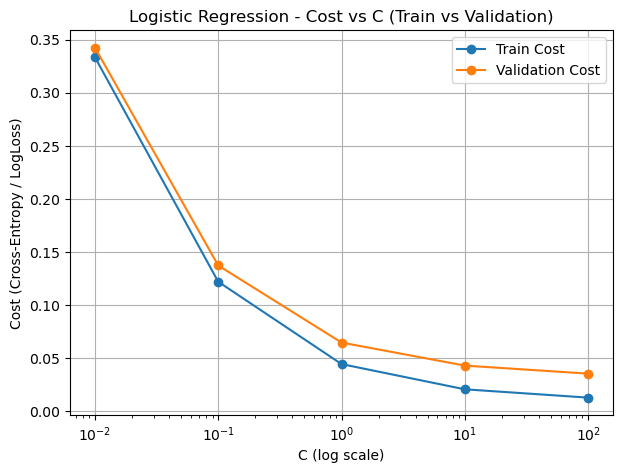

In [65]:
# Plot Train vs Validation (Cost) across C

def lookup(df, C, col):
    return float(df[df["C"] == C][col].values[0])

train_costs = [lookup(results, C, "Train Cost (LogLoss)") for C in C_list]
val_costs   = [lookup(results, C, "Val Cost (LogLoss)") for C in C_list]

plt.figure(figsize=(7,5))
plt.plot(C_list, train_costs, marker='o', label="Train Cost")
plt.plot(C_list, val_costs, marker='o', label="Validation Cost")
plt.xscale("log")
plt.xlabel("C (log scale)")
plt.ylabel("Cost (Cross-Entropy / LogLoss)")
plt.title("Logistic Regression - Cost vs C (Train vs Validation)")
plt.grid(True)
plt.legend()
plt.show()

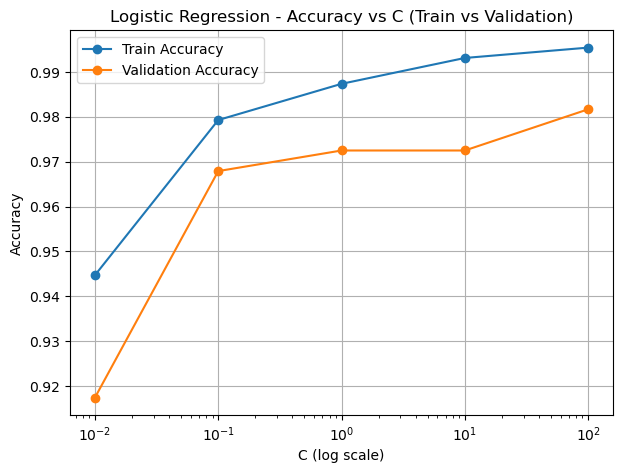

In [67]:
# Plot Train vs Validation (Accuracy) across C
train_accs = [lookup(results, C, "Train Accuracy") for C in C_list]
val_accs   = [lookup(results, C, "Val Accuracy") for C in C_list]

plt.figure(figsize=(7,5))
plt.plot(C_list, train_accs, marker='o', label="Train Accuracy")
plt.plot(C_list, val_accs, marker='o', label="Validation Accuracy")
plt.xscale("log")
plt.xlabel("C (log scale)")
plt.ylabel("Accuracy")
plt.title("Logistic Regression - Accuracy vs C (Train vs Validation)")
plt.grid(True)
plt.legend()
plt.show()

In [71]:
# Final Training (Train+Val) with best C, then evaluate on Test

X_train_full = pd.concat([X_tr, X_val])
y_train_full = pd.concat([y_tr, y_val])

final_model = LogisticRegression(C=best_C, max_iter=2000)
final_model.fit(X_train_full, y_train_full)

test_proba = final_model.predict_proba(X_test_scaled)
test_pred = final_model.predict(X_test_scaled)

test_cost = log_loss(y_test, test_proba)
test_acc = accuracy_score(y_test, test_pred)

print("\n=== Final Test Evaluation (using best C) ===")
print("Test Cost (LogLoss):", test_cost)
print("Test Accuracy:", test_acc)



=== Final Test Evaluation (using best C) ===
Test Cost (LogLoss): 0.021952485241473092
Test Accuracy: 0.9927272727272727


## SVM algorithm with leanier and RBF kernels

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Split Train (Train/Validation)
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_scaled, y_train_clean,
    test_size=0.2,
    random_state=42,
    stratify=y_train_clean
)

# Hinge loss (Cost Function) using decision_function
# y must be in {-1, +1}
def hinge_loss(y_true_01, decision_scores):
    y = np.where(np.asarray(y_true_01) == 1, 1, -1)  # 0/1 to -1/+1
    margins = 1 - y * decision_scores
    return np.mean(np.maximum(0, margins))

# Hyperparameter grids
C_list = [0.01, 0.1, 1, 10, 100]          
gamma_list = [0.01, 0.1, 1]        # for RBF

rows = []

# Evaluate LINEAR kernel
for C in C_list:
    model = SVC(kernel="linear", C=C)

    model.fit(X_tr, y_tr)

    # accuracy
    y_tr_pred = model.predict(X_tr)
    y_val_pred = model.predict(X_val)

    tr_acc = accuracy_score(y_tr, y_tr_pred)
    val_acc = accuracy_score(y_val, y_val_pred)

    # hinge loss cost
    tr_score = model.decision_function(X_tr)
    val_score = model.decision_function(X_val)

    tr_cost = hinge_loss(y_tr, tr_score)
    val_cost = hinge_loss(y_val, val_score)

    rows.append({
        "kernel": "linear",
        "C": C,
        "gamma": np.nan,
        "Train Accuracy": tr_acc,
        "Val Accuracy": val_acc,
        "Train Cost (Hinge)": tr_cost,
        "Val Cost (Hinge)": val_cost,
        "Acc Gap (Train-Val)": tr_acc - val_acc,
        "Cost Gap (Val-Train)": val_cost - tr_cost
    })

# Evaluate RBF kernel
for gamma in gamma_list:
    for C in C_list:
        model = SVC(kernel="rbf", C=C, gamma=gamma)

        model.fit(X_tr, y_tr)

        # accuracy
        y_tr_pred = model.predict(X_tr)
        y_val_pred = model.predict(X_val)

        tr_acc = accuracy_score(y_tr, y_tr_pred)
        val_acc = accuracy_score(y_val, y_val_pred)

        # hinge loss cost
        tr_score = model.decision_function(X_tr)
        val_score = model.decision_function(X_val)

        tr_cost = hinge_loss(y_tr, tr_score)
        val_cost = hinge_loss(y_val, val_score)

        rows.append({
            "kernel": "rbf",
            "C": C,
            "gamma": gamma,
            "Train Accuracy": tr_acc,
            "Val Accuracy": val_acc,
            "Train Cost (Hinge)": tr_cost,
            "Val Cost (Hinge)": val_cost,
            "Acc Gap (Train-Val)": tr_acc - val_acc,
            "Cost Gap (Val-Train)": val_cost - tr_cost
        })

results_svm = pd.DataFrame(rows)

# Minimum Val Cost (Hinge)
results_sorted = results_svm.sort_values(by="Val Cost (Hinge)", ascending=True).reset_index(drop=True)
from IPython.display import display, HTML

table_for_report = results_sorted.copy()

# Round numbers
table_for_report["Train Accuracy"] = table_for_report["Train Accuracy"].round(4)
table_for_report["Val Accuracy"] = table_for_report["Val Accuracy"].round(4)
table_for_report["Train Cost (Hinge)"] = table_for_report["Train Cost (Hinge)"].round(6)
table_for_report["Val Cost (Hinge)"] = table_for_report["Val Cost (Hinge)"].round(6)
table_for_report["Acc Gap (Train-Val)"] = table_for_report["Acc Gap (Train-Val)"].round(6)
table_for_report["Cost Gap (Val-Train)"] = table_for_report["Cost Gap (Val-Train)"].round(6)

display(HTML(table_for_report.to_html(index=False)))
                                     
# Best row (minimum Validation Cost)
best_row = results_sorted.iloc[0]

best_kernel = best_row["kernel"]
best_C = float(best_row["C"])
best_gamma = best_row["gamma"] if pd.notna(best_row["gamma"]) else None


print("\nBest SVM based on minimum Validation Cost (Hinge):")
print("kernel =", best_kernel, "| C =", best_C, "| gamma =", best_gamma)


kernel,C,gamma,Train Accuracy,Val Accuracy,Train Cost (Hinge),Val Cost (Hinge),Acc Gap (Train-Val),Cost Gap (Val-Train)
rbf,100.00,0.10,1.0000,1.0000,0.000036,0.001403,0.000000,0.001366
rbf,100.00,1.00,1.0000,1.0000,0.000006,0.005232,0.000000,0.005226
rbf,10.00,1.00,1.0000,1.0000,0.000010,0.005244,0.000000,0.005235
rbf,10.00,0.10,1.0000,1.0000,0.003753,0.006980,0.000000,0.003227
rbf,1.00,1.00,1.0000,1.0000,0.003675,0.010294,0.000000,0.006619
rbf,100.00,0.01,1.0000,1.0000,0.009675,0.023298,0.000000,0.013623
rbf,1.00,0.10,0.9977,0.9908,0.028350,0.039658,0.006870,0.011308
linear,100.00,NaN,0.9954,0.9817,0.011271,0.042168,0.013740,0.030896
linear,10.00,NaN,0.9965,0.9817,0.015626,0.046073,0.014892,0.030447
rbf,10.00,0.01,0.9885,0.9771,0.032232,0.050092,0.011415,0.017860



Best SVM based on minimum Validation Cost (Hinge):
kernel = rbf | C = 100.0 | gamma = 0.1


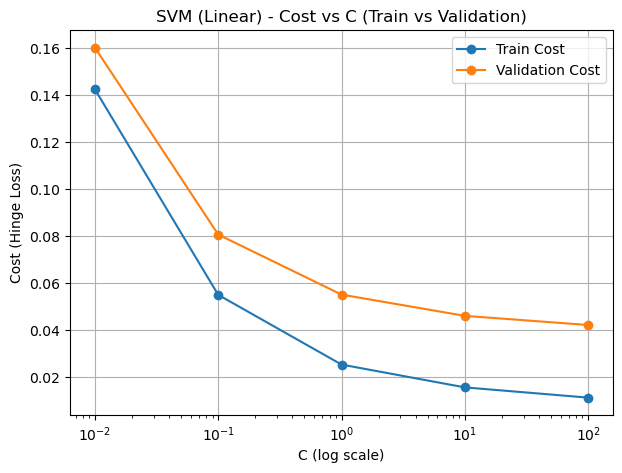

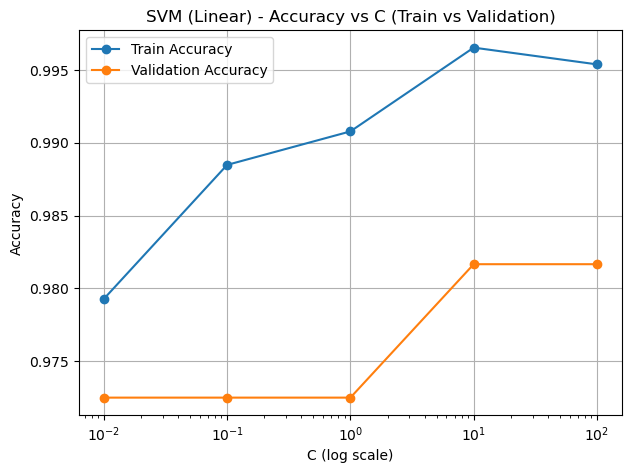

In [77]:
# Plots (Train vs Val) - Linear kernel
lin = results_svm[results_svm["kernel"] == "linear"].sort_values("C")

plt.figure(figsize=(7,5))
plt.plot(lin["C"], lin["Train Cost (Hinge)"], marker='o', label="Train Cost")
plt.plot(lin["C"], lin["Val Cost (Hinge)"], marker='o', label="Validation Cost")
plt.xscale("log")
plt.xlabel("C (log scale)")
plt.ylabel("Cost (Hinge Loss)")
plt.title("SVM (Linear) - Cost vs C (Train vs Validation)")
plt.grid(True)
plt.legend()
plt.show()

plt.figure(figsize=(7,5))
plt.plot(lin["C"], lin["Train Accuracy"], marker='o', label="Train Accuracy")
plt.plot(lin["C"], lin["Val Accuracy"], marker='o', label="Validation Accuracy")
plt.xscale("log")
plt.xlabel("C (log scale)")
plt.ylabel("Accuracy")
plt.title("SVM (Linear) - Accuracy vs C (Train vs Validation)")
plt.grid(True)
plt.legend()
plt.show()

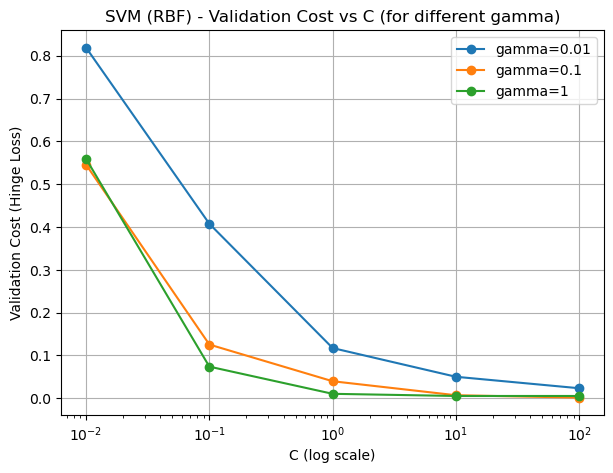

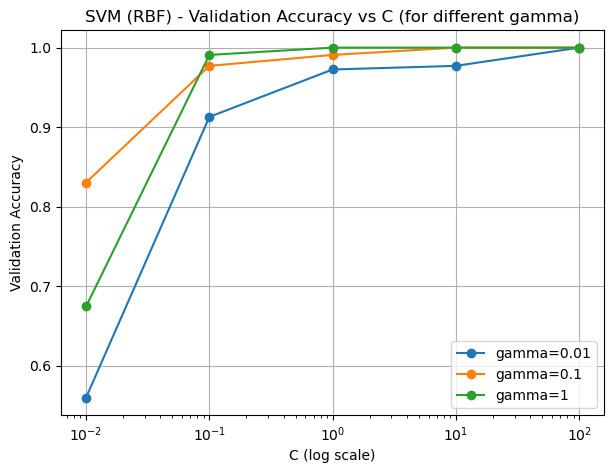

In [79]:
# Plots (Train vs Val) - RBF kernel
rbf = results_svm[results_svm["kernel"] == "rbf"].copy()

plt.figure(figsize=(7,5))
for gamma in gamma_list:
    tmp = rbf[rbf["gamma"] == gamma].sort_values("C")
    plt.plot(tmp["C"], tmp["Val Cost (Hinge)"], marker='o', label=f"gamma={gamma}")

plt.xscale("log")
plt.xlabel("C (log scale)")
plt.ylabel("Validation Cost (Hinge Loss)")
plt.title("SVM (RBF) - Validation Cost vs C (for different gamma)")
plt.grid(True)
plt.legend()
plt.show()

plt.figure(figsize=(7,5))
for gamma in gamma_list:
    tmp = rbf[rbf["gamma"] == gamma].sort_values("C")
    plt.plot(tmp["C"], tmp["Val Accuracy"], marker='o', label=f"gamma={gamma}")

plt.xscale("log")
plt.xlabel("C (log scale)")
plt.ylabel("Validation Accuracy")
plt.title("SVM (RBF) - Validation Accuracy vs C (for different gamma)")
plt.grid(True)
plt.legend()
plt.show()


In [81]:
# Final training on Train+Val with best params, then evaluate on Test
X_train_full = np.vstack([X_tr, X_val])
y_train_full = np.hstack([y_tr, y_val])

if best_kernel == "linear":
    final_svm = SVC(kernel="linear", C=best_C)
else:
    final_svm = SVC(kernel="rbf", C=best_C, gamma=float(best_gamma))

final_svm.fit(X_train_full, y_train_full)

X_test_np = np.asarray(X_test_scaled)
test_pred = final_svm.predict(X_test_np)
test_acc = accuracy_score(y_test, test_pred)

test_score = final_svm.decision_function(X_test_np)
test_cost = hinge_loss(y_test, test_score)

print("\n=== Final Test Evaluation (Best SVM) ===")
print("Test Cost (Hinge):", test_cost)
print("Test Accuracy:", test_acc)



=== Final Test Evaluation (Best SVM) ===
Test Cost (Hinge): 1.2812196957686952e-06
Test Accuracy: 1.0


## K-Means algorithm for clustering

K-Means Cost (Inertia): 2666.708079606419


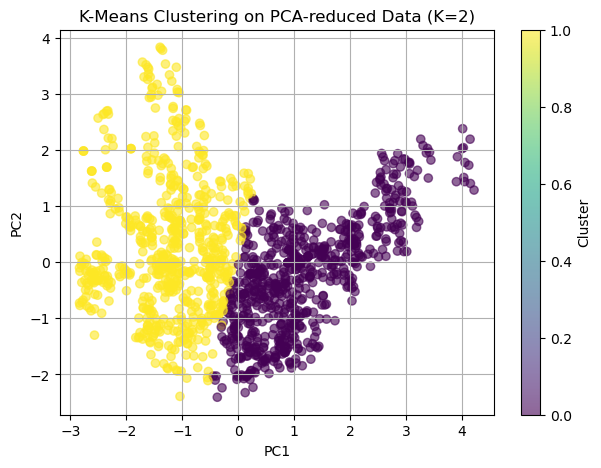

Best clustering accuracy: 0.5540044085231447


,True=1,True=0
Pred=1,349,252
Pred=0,355,405


In [95]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from IPython.display import display, HTML
from sklearn.metrics import accuracy_score, confusion_matrix

# combine train and test for unsupervised algorithm
X_pca_all = np.vstack([X_train_pca, X_test_pca])

# K-means (k=2)
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_pca_all)

print("K-Means Cost (Inertia):", kmeans.inertia_)

# plot clustering
plt.figure(figsize=(7,5))
plt.scatter(X_pca_all[:, 0], X_pca_all[:, 1], c=clusters, alpha=0.6)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("K-Means Clustering on PCA-reduced Data (K=2)")
plt.colorbar(label="Cluster")
plt.grid(True)
plt.show()

# compare with true labels
y_all = np.hstack([y_train_clean.to_numpy(), y_test.to_numpy()])

acc1 = accuracy_score(y_all, clusters)
acc2 = accuracy_score(y_all, 1 - clusters)

best_acc = max(acc1, acc2)
best_pred = clusters if acc1 >= acc2 else (1 - clusters)

print("Best clustering accuracy:", best_acc)

cm = confusion_matrix(y_all, best_pred, labels=[1, 0])

cm_df = pd.DataFrame(
    cm,
    index=["Pred=1", "Pred=0"],
    columns=["True=1", "True=0"]
)

display(HTML(cm_df.to_html()))